# True per-category change after fine-tuning

For every parent & fine-tuned child pair, compare their real answers on all MMLU questions,
per category (STEM, humanities, social sciences, other) and subject.

Question: do fine-tunes ever improve one category/subject while hurting another (a trade-off)?

No IRT is used here, this data analysis is purely on response matrix

In [32]:
import sys

sys.path.insert(0, "../scripts/irt")

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import LinearSegmentedColormap
from efficbench_pairs import LINEAGE, load_with_parents

from cabench.pairs import drop_near_duplicates

Z = 2  # a change is "valid" if it is more than 2 standard errors from 0 (about 95% confidence)

## Load the answers

`Y[m, q]` = 1 if LLM `m` got question `q` right, else 0. `names[m]` is the LLM's name and `items.subject[q]` is the question's MMLU subject

In [33]:
Y, names, items, _ = load_with_parents()
assert len(set(names)) == len(names), "LLM names must be unique"
row = {name: i for i, name in enumerate(names)}  # model name : row number in Y
print(f"{Y.shape[0]} LLMs x {Y.shape[1]} questions")

452 LLMs x 14042 questions


## Find the pairs
A pair is usable only if both LLMs are in `Y`. If one parent has several children that answer over 99% of questions identically, only one is kept, so a near copy isn't counted twice

In [34]:
lineage = pd.read_csv(LINEAGE)
# print(lineage["evidence"].unique())
# print(lineage["use"].unique())

tested = lineage[lineage["use"] != "related"] # keep fine-tuned and version step pairs
has_both = tested.child.isin(row) & tested.parent.isin(row) # both exist in Y
usable = tested[has_both].reset_index(drop=True) 
pairs = drop_near_duplicates(usable, Y, names) # drop near duplicates

print(f"{len(tested)} fine-tune or version step pairs") 
print(f"{len(usable)} usable (both LLMs in Y)") 
print(f"{len(pairs)} after removing near copies")
print("breakdown by type:", pairs["use"].value_counts().to_dict())
missing = sorted(set(tested[~has_both].parent) - set(row))
print(f"{len(missing)} parents missing from Y (the download would add these):", missing)

98 fine-tune or version step pairs
98 usable (both LLMs in Y)
97 after removing near copies
breakdown by type: {'fine-tuned': 90, 'version step': 7}
0 parents missing from Y (the download would add these): []


## Subjects mapping to 4 categories

MMLU's standard grouping (Hendrycks et al., 2021). Categories have a large amount of questions each, so their changes are far less noisy than the 57 single subjects

In [35]:
STEM = ["abstract_algebra", "astronomy", "college_biology", "college_chemistry",
        "college_computer_science", "college_mathematics", "college_physics", "computer_security",
        "conceptual_physics", "electrical_engineering", "elementary_mathematics",
        "high_school_biology", "high_school_chemistry", "high_school_computer_science",
        "high_school_mathematics", "high_school_physics", "high_school_statistics", "machine_learning"]
HUMANITIES = ["formal_logic", "high_school_european_history", "high_school_us_history",
              "high_school_world_history", "international_law", "jurisprudence", "logical_fallacies",
              "moral_disputes", "moral_scenarios", "philosophy", "prehistory", "professional_law",
              "world_religions"]
SOCIAL = ["econometrics", "high_school_geography", "high_school_government_and_politics",
          "high_school_macroeconomics", "high_school_microeconomics", "high_school_psychology",
          "human_sexuality", "professional_psychology", "public_relations", "security_studies",
          "sociology", "us_foreign_policy"]
OTHER = ["anatomy", "business_ethics", "clinical_knowledge", "college_medicine", "global_facts",
         "human_aging", "management", "marketing", "medical_genetics", "miscellaneous", "nutrition",
         "professional_accounting", "professional_medicine", "virology"]

CATEGORY = {s: c for c, subjects in [("STEM", STEM), ("humanities", HUMANITIES),
                                      ("social sciences", SOCIAL), ("other", OTHER)] for s in subjects}

cats = items.subject.map(CATEGORY).to_numpy() # replace subject with its category
print(pd.Series(cats).value_counts())

humanities         4705
other              3242
social sciences    3077
STEM               3018
Name: count, dtype: int64


## Per-question difference for each pair

For a pair, `delta[q] = child's answer − parent's answer` on question q:

+1 = child gained it, −1 = child lost it, 0 = no change.

The mean of `delta` over a category's questions is the change in accuracy on that category

In [36]:
child_rows = pairs.child.map(row).to_numpy()
parent_rows = pairs.parent.map(row).to_numpy()
delta = Y[child_rows] - Y[parent_rows]  
print(delta.shape) # (pairs, questions)
print(delta[:5])

(97, 14042)
[[ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0.  0.]
 [ 0.  0.  0. ...  0.  0. -1.]
 [ 0.  0.  0. ...  0.  0.  0.]]


## *Change and its uncertainty per category

- change = mean of delta within the category
- standard error (se) = standard deviation / sqrt(number of questions)
- z = change / se. |z| > 2 means the change is clearly bigger than chance (about 95%)

In [37]:
group_mean = pd.DataFrame(delta.T).groupby(cats).mean().T
change = group_mean.set_axis(pairs.child, axis=0)

n = pd.Series(cats).value_counts()
group_se = pd.DataFrame(delta.T).groupby(cats).std().T / np.sqrt(n)
se = group_se.set_axis(pairs.child, axis=0)

z = change / se
change["overall"] = delta.mean(1)
(100 * change).round(1).sort_values(by="overall", key=abs, ascending=False).head(10) # in percentage points

,STEM,humanities,other,social sciences,overall
child,,,,,
ehartford/WizardLM-1.0-Uncensored-CodeLlama-34b,11.2,19.0,16.0,22.200001,17.299999
ehartford/Samantha-1.11-CodeLlama-34b,10.8,18.4,14.7,20.299999,16.299999
Locutusque/Rhino-Mistral-7B,-11.8,-11.8,-16.6,-20.100000,-14.800000
rameshm/llama-2-13b-mathgpt-v4,-6.7,-11.2,-12.9,-12.100000,-10.800000
teknium/Mistral-Trismegistus-7B,-7.1,-7.9,-10.4,-13.200000,-9.500000
mistralai/Mistral-7B-Instruct-v0.1,-7.0,-8.2,-9.4,-11.400000,-8.900000
zyh3826/llama2-13b-ft-openllm-leaderboard-v1,4.8,7.4,6.8,7.800000,6.800000
qblocks/codellama_7b_DolphinCoder,3.2,5.4,6.1,9.900000,6.100000
rombodawg/LosslessMegaCoder-llama2-7b-mini,4.5,5.1,5.8,9.500000,6.100000


## How many pairs show a trade-off?

Each category of each pair is clearly up if z > 2, clearly down if z < −2 or unclear.

A trade-off = model improved in one category but worsened in another

In [38]:
status = np.sign(z.where(z.abs() > Z, 0)) # check significance
tradeoff = (status == 1).any(axis=1) & (status == -1).any(axis=1) # clearly up in one cat AND clearly down in another cat

print(f"{tradeoff.sum()} of {len(pairs)} pairs show a trade-off")
print(f"{((status != 0).sum(axis=1) == 0).sum()} pairs: no clear change in any category")
pd.DataFrame({"clearly up": (status == 1).sum(), "clearly down": (status == -1).sum()})

5 of 97 pairs show a trade-off
19 pairs: no clear change in any category


,clearly up,clearly down
STEM,14,25
humanities,35,22
other,25,27
social sciences,25,31


## Pairwise comparison of categories
Answers: how many pairs have categories that changed by clearly different amounts?

In [39]:
cols = ["STEM", "humanities", "social sciences", "other"]
Z_PAIR = 2.64  # stricter than 2: we make 6 comparisons per pair, so 2 would give too many false alarms

different = {}
for i, a in enumerate(cols):
    for b in cols[i + 1:]:
        z_pair = (change[a] - change[b]) / np.sqrt(se[a] ** 2 + se[b] ** 2)
        different[f"{a} vs {b}"] = z_pair.abs() > Z_PAIR
different = pd.DataFrame(different)

print(f"{different.any(axis=1).sum()} of {len(pairs)} pairs: at least two categories changed by clearly different amounts")
different.sum()

45 of 97 pairs: at least two categories changed by clearly different amounts


STEM vs humanities               19
STEM vs social sciences          14
STEM vs other                     6
humanities vs social sciences    24
humanities vs other              22
social sciences vs other          6
dtype: int64

## Picture: every pair x every category

Red = got worse, green = got better (percentage points). Rows sorted by overall change

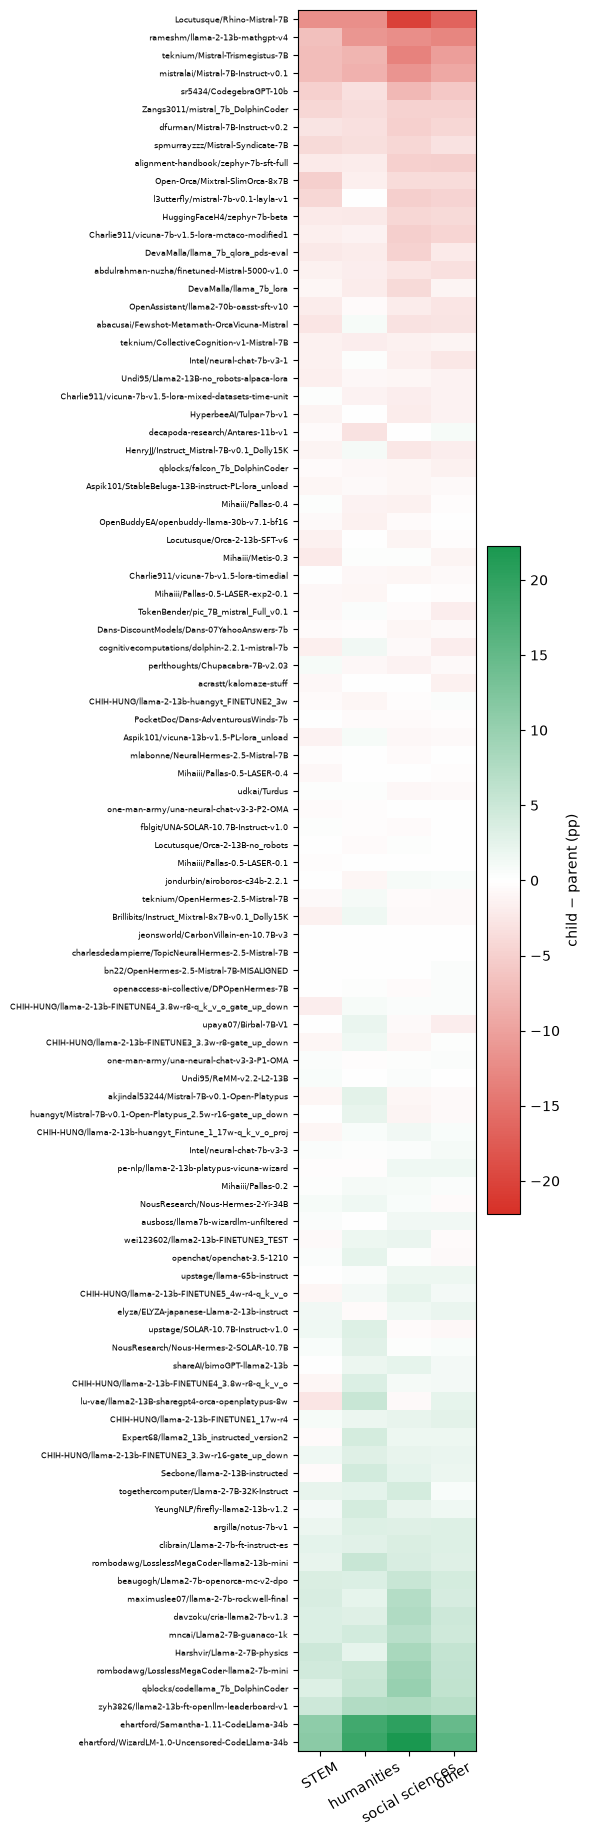

In [40]:
red_green = LinearSegmentedColormap.from_list("red_green", ["#d73027", "white", "#1a9850"])

order = change.sort_values("overall").index
shown = 100 * change.loc[order, ["STEM", "humanities", "social sciences", "other"]]
limit = np.abs(shown.to_numpy()).max()

fig, ax = plt.subplots(figsize=(6, 0.18 * len(shown) + 1))
im = ax.imshow(shown, cmap=red_green, vmin=-limit, vmax=limit, aspect="auto")
ax.set_xticks(range(4), shown.columns, rotation=30)
ax.set_yticks(range(len(shown)), shown.index, fontsize=6)
fig.colorbar(im, label="child − parent (pp)")
plt.tight_layout()

## Sanity check on pairs we can predict

Maths fine-tunes (e.g. MetaMath) should, if anything, move STEM. Code models should move STEM / computer science.

In [41]:
known = change.index.str.contains("MetaMath|Math|Code", case=False)
display((100 * change[known]).round(1))
display(status[known])

,STEM,humanities,other,social sciences,overall
child,,,,,
ehartford/Samantha-1.11-CodeLlama-34b,10.8,18.4,14.7,20.299999,16.299999
ehartford/WizardLM-1.0-Uncensored-CodeLlama-34b,11.2,19.0,16.0,22.200001,17.299999
qblocks/codellama_7b_DolphinCoder,3.2,5.4,6.1,9.900000,6.100000
rameshm/llama-2-13b-mathgpt-v4,-6.7,-11.2,-12.9,-12.100000,-10.800000
rombodawg/LosslessMegaCoder-llama2-13b-mini,2.3,5.3,3.0,3.800000,3.800000
rombodawg/LosslessMegaCoder-llama2-7b-mini,4.5,5.1,5.8,9.500000,6.100000
Zangs3011/mistral_7b_DolphinCoder,-4.2,-3.6,-4.8,-4.700000,-4.300000
abacusai/Fewshot-Metamath-OrcaVicuna-Mistral,-2.6,0.8,-2.8,-3.100000,-1.600000
qblocks/falcon_7b_DolphinCoder,-0.4,-0.7,-1.4,-0.900000,-0.900000


,STEM,humanities,other,social sciences
child,,,,
ehartford/Samantha-1.11-CodeLlama-34b,1.0,1.0,1.0,1.0
ehartford/WizardLM-1.0-Uncensored-CodeLlama-34b,1.0,1.0,1.0,1.0
qblocks/codellama_7b_DolphinCoder,1.0,1.0,1.0,1.0
rameshm/llama-2-13b-mathgpt-v4,-1.0,-1.0,-1.0,-1.0
rombodawg/LosslessMegaCoder-llama2-13b-mini,1.0,1.0,1.0,1.0
rombodawg/LosslessMegaCoder-llama2-7b-mini,1.0,1.0,1.0,1.0
Zangs3011/mistral_7b_DolphinCoder,-1.0,-1.0,-1.0,-1.0
abacusai/Fewshot-Metamath-OrcaVicuna-Mistral,-1.0,0.0,-1.0,-1.0
qblocks/falcon_7b_DolphinCoder,0.0,0.0,0.0,0.0


## Takeaways:
- clear trade offs are rare - about 5%. In most pairs, the categories that change all move together 
- 78/97 pairs had at least one category which had a significant change. 19/97 had no change 
- categories did not go up/down equal amount of times. Eg: STEM went down more than up, Humanities went up more than down. This could just be because of what it was fine tuned for but worth doing a deeper dive using MIRT
- over 50% of pairs had at least 2 categorues changing by different amounts
- Sanity check: the STEM specific fine tunes (coding and maths) actually improve the other categories more than STEM. Possible reason is that MMLU's STEM questions are knowledge questions? Need to extend this to other benchmarks too